# Exercise 3 — MLP

Neste exercício implementei um MLP do zero em NumPy. O Exercise 1 é uma etapa de backpropagation feita à
mão. O Exercise 2 é um problema binário que uma reta não resolve. O Exercise 3 usa a mesma rede em um
problema com três classes. O Exercise 4 testa se uma segunda camada oculta ajuda.

**Como fiz.**

- O MLP está em `mlp.py` (a primeira célula de código abaixo), em uma classe `MLP`. Os tamanhos das camadas são um argumento
  (por exemplo `[2, 8, 1]`). A classe tem as ativações, a perda, o forward, o backward com todos os gradientes
  escritos à mão e o update por gradiente descendente. Não usei nenhuma biblioteca de redes neurais.
- As camadas ocultas usam tanh. A saída usa sigmoide no caso binário e softmax no caso multiclasse. A perda é a
  entropia cruzada (binária ou categórica). Nos dois casos o gradiente na saída é
  $\partial L / \partial \mathbf{u} = (\hat{\mathbf{y}} - \mathbf{y})/N$, então o mesmo código de backward serve
  para os Exercises 2, 3 e 4 sem nenhuma alteração. Só mudam os argumentos.
- Os pesos começam com $\mathcal{N}(0,\ 1/n_{\text{entradas}})$ e os vieses em zero. O treino é em lote
  completo (todas as amostras de treino a cada época).
- O scikit-learn foi usado só para gerar os dados, dividir treino e teste, calcular a matriz de confusão e
  rodar as regressões logísticas de baseline, como o enunciado permite.
- Cada script começa com `rng = np.random.default_rng(42)`, e esse `rng` inicializa os pesos da rede. No
  Exercise 4, onde o enunciado pede pelo menos 3 seeds, cada execução usa `default_rng(seed)` com
  seed 42, 43 e 44. A execução com seed 42 é a mesma do Exercise 3.

Este notebook junta o código dos scripts `mlp.py`, `multiclass_data.py`, `ex2_binary.py`, `ex3_multiclass.py` e `ex4_depth.py`, na mesma ordem. Cada exercício recria `rng = np.random.default_rng(42)`, como os scripts, então os números são os mesmos.

In [1]:
"""MLP escrito do zero em NumPy, usado nos Exercises 2, 3 e 4.

O mesmo código de forward, backward e update serve para classificação binária
(saída sigmoide + entropia cruzada binária) e multiclasse (saída softmax +
entropia cruzada categórica). Só mudam os argumentos: tamanhos das camadas,
tipo de saída, taxa de aprendizado e gerador aleatório.

Notação da aula: em cada camada, u = W a + b, com W no formato
(neurônios que recebem, neurônios que enviam).
"""
import numpy as np


class MLP:
    def __init__(self, layer_sizes, output="sigmoid", lr=0.1, rng=None):
        """layer_sizes: lista com o tamanho de cada camada, ex. [2, 8, 1].
        output: "sigmoid" (binário, 1 neurônio de saída) ou "softmax" (multiclasse).
        lr: taxa de aprendizado do gradiente descendente.
        rng: np.random.Generator usado para inicializar os pesos.
        """
        self.layer_sizes = layer_sizes
        self.output = output
        self.lr = lr
        # Pesos com desvio 1/sqrt(n_entradas) (inicialização de Xavier, boa para tanh); vieses em zero
        self.W = [rng.normal(0.0, np.sqrt(1.0 / n_in), size=(n_out, n_in))
                  for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:])]
        self.b = [np.zeros(n_out) for n_out in layer_sizes[1:]]

    # ------------------------------------------------------------ ativações
    @staticmethod
    def tanh(u):
        return np.tanh(u)

    @staticmethod
    def sigmoid(u):
        return 1.0 / (1.0 + np.exp(-np.clip(u, -500, 500)))

    @staticmethod
    def softmax(u):
        e = np.exp(u - u.max(axis=1, keepdims=True))   # subtrai o máximo para não estourar
        return e / e.sum(axis=1, keepdims=True)

    # ------------------------------------------------------------ forward
    def forward(self, X):
        """X: (N, n_entradas). Guarda a saída de cada camada para usar no backward."""
        self.activations = [X]
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            u = self.activations[-1] @ W.T + b          # pré-ativação da camada
            if i < len(self.W) - 1:
                a = self.tanh(u)                        # camadas ocultas: tanh
            elif self.output == "sigmoid":
                a = self.sigmoid(u)
            else:
                a = self.softmax(u)
            self.activations.append(a)
        return self.activations[-1]

    # ------------------------------------------------------------ perda
    def loss(self, Y_hat, Y):
        """Entropia cruzada média. Y tem o mesmo formato de Y_hat (one-hot no caso multiclasse)."""
        eps = 1e-12
        if self.output == "sigmoid":
            return float(-np.mean(Y * np.log(Y_hat + eps) + (1 - Y) * np.log(1 - Y_hat + eps)))
        return float(-np.mean(np.sum(Y * np.log(Y_hat + eps), axis=1)))

    # ------------------------------------------------------------ backward
    def backward(self, Y):
        """Calcula os gradientes de todos os pesos e vieses (regra da cadeia, sem autodiff).

        Tanto sigmoide + BCE quanto softmax + entropia cruzada categórica dão
        dL/du = (Y_hat - Y) / N na saída, então o mesmo código serve aos dois casos.
        """
        N = Y.shape[0]
        delta = (self.activations[-1] - Y) / N          # dL/du da camada de saída
        self.grad_W = [None] * len(self.W)
        self.grad_b = [None] * len(self.b)
        for i in reversed(range(len(self.W))):
            self.grad_W[i] = delta.T @ self.activations[i]   # dL/dW = delta^T a_anterior
            self.grad_b[i] = delta.sum(axis=0)               # dL/db = soma dos deltas
            if i > 0:
                # volta uma camada: dL/da = delta W, e multiplica pela derivada da tanh (1 - a^2)
                delta = (delta @ self.W[i]) * (1 - self.activations[i] ** 2)

    # ------------------------------------------------------------ update
    def update(self):
        """Gradiente descendente: p <- p - lr * dL/dp."""
        for i in range(len(self.W)):
            self.W[i] -= self.lr * self.grad_W[i]
            self.b[i] -= self.lr * self.grad_b[i]

    # ------------------------------------------------------------ treino e previsão
    def fit(self, X, Y, epochs):
        """Treino em lote completo. Devolve a perda de treino de cada época."""
        history = []
        for _ in range(epochs):
            Y_hat = self.forward(X)
            history.append(self.loss(Y_hat, Y))
            self.backward(Y)
            self.update()
        return np.array(history)

    def predict(self, X):
        Y_hat = self.forward(X)
        if self.output == "sigmoid":
            return (Y_hat[:, 0] >= 0.5).astype(int)
        return Y_hat.argmax(axis=1)

    def n_params(self):
        return int(sum(W.size + b.size for W, b in zip(self.W, self.b)))


In [2]:
"""Dados dos Exercises 3 e 4 (os dois usam exatamente o mesmo conjunto e a mesma divisão)."""
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split


def load_multiclass():
    """1500 amostras, 4 features informativas, 3 classes, 2 clusters por classe; divisão 80/20 estratificada."""
    X, y = make_classification(n_samples=1500, n_features=4, n_informative=4, n_redundant=0,
                               n_repeated=0, n_classes=3, n_clusters_per_class=2,
                               class_sep=1.0, random_state=42)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    return X_train, X_test, y_train, y_test


def one_hot(y, n_classes=3):
    return np.eye(n_classes)[y]


---
## Exercise 1

**One Step of Backpropagation, by Hand.** Rede 2-2-1 com tanh nas duas camadas e perda $L = (y - \hat y)^2$ para uma amostra. Valores dados:
$\mathbf{x} = [0.5,\ -0.2]$, $y = 1$, $W^{(1)} = \begin{bmatrix}0.3 & -0.1\\ 0.2 & 0.4\end{bmatrix}$,
$\mathbf{b}^{(1)} = [0.1,\ -0.2]$, $W^{(2)} = [0.5,\ -0.3]$, $b^{(2)} = 0.2$ e $\eta = 0.3$. Fiz as contas à mão
e mantive 6 casas nos cálculos intermediários; os resultados estão com 4 casas.

### A — Forward pass

**Pré-ativações da camada oculta**, $\mathbf{z}^{(1)} = W^{(1)}\mathbf{x} + \mathbf{b}^{(1)}$:

$$z^{(1)}_1 = 0.3(0.5) + (-0.1)(-0.2) + 0.1 = 0.15 + 0.02 + 0.1 = 0.2700$$

$$z^{(1)}_2 = 0.2(0.5) + 0.4(-0.2) - 0.2 = 0.10 - 0.08 - 0.2 = -0.1800$$

**Ativações da camada oculta**, $\mathbf{h}^{(1)} = \tanh(\mathbf{z}^{(1)})$:

$$h^{(1)}_1 = \tanh(0.27) = 0.2636, \qquad h^{(1)}_2 = \tanh(-0.18) = -0.1781$$

**Pré-ativação da saída**, $u^{(2)} = W^{(2)}\mathbf{h}^{(1)} + b^{(2)}$:

$$u^{(2)} = 0.5(0.263625) + (-0.3)(-0.178081) + 0.2 = 0.131813 + 0.053424 + 0.2 = 0.3852$$

**Saída e perda:**

$$\hat y = \tanh(0.385237) = 0.3672, \qquad L = (1 - 0.367247)^2 = (0.632753)^2 = 0.4004$$

### B — Backward pass

Comecei por $\partial L / \partial \hat y$ e fui aplicando a regra da cadeia para trás. A derivada da tanh é
$1 - \tanh^2(u)$.

**1. Saída.**

$$\frac{\partial L}{\partial \hat y} = -2(y - \hat y) = -2(0.632753) = -1.2655$$

$$\frac{\partial \hat y}{\partial u^{(2)}} = 1 - \hat y^2 = 1 - 0.367247^2 = 0.8651$$

$$\frac{\partial L}{\partial u^{(2)}} = \frac{\partial L}{\partial \hat y}\cdot\frac{\partial \hat y}{\partial u^{(2)}}
= -1.265507 \times 0.865130 = -1.0948$$

**2. Camada de saída.** Como $u^{(2)} = W^{(2)}\mathbf{h}^{(1)} + b^{(2)}$:

$$\frac{\partial L}{\partial W^{(2)}} = \frac{\partial L}{\partial u^{(2)}}\,\mathbf{h}^{(1)}
= -1.094828 \times [0.263625,\ -0.178081] = [-0.2886,\ 0.1950]$$

$$\frac{\partial L}{\partial b^{(2)}} = \frac{\partial L}{\partial u^{(2)}} = -1.0948$$

**3. De volta para a camada oculta.**

$$\frac{\partial L}{\partial \mathbf{h}^{(1)}} = \frac{\partial L}{\partial u^{(2)}}\,W^{(2)}
= -1.094828 \times [0.5,\ -0.3] = [-0.5474,\ 0.3284]$$

$$1 - (\mathbf{h}^{(1)})^2 = [1 - 0.263625^2,\ 1 - 0.178081^2] = [0.9305,\ 0.9683]$$

$$\frac{\partial L}{\partial \mathbf{z}^{(1)}} = \frac{\partial L}{\partial \mathbf{h}^{(1)}} \odot \left(1 - (\mathbf{h}^{(1)})^2\right)
= [-0.547414 \times 0.930502,\ 0.328448 \times 0.968287] = [-0.5094,\ 0.3180]$$

**4. Camada oculta.** Como $\mathbf{z}^{(1)} = W^{(1)}\mathbf{x} + \mathbf{b}^{(1)}$, cada linha do gradiente de
$W^{(1)}$ é o $\partial L/\partial z_j$ daquele neurônio vezes $\mathbf{x}$:

$$\frac{\partial L}{\partial W^{(1)}} = \frac{\partial L}{\partial \mathbf{z}^{(1)}}\,\mathbf{x}^\top
= \begin{bmatrix}-0.509370(0.5) & -0.509370(-0.2)\\ 0.318032(0.5) & 0.318032(-0.2)\end{bmatrix}
= \begin{bmatrix}-0.2547 & 0.1019\\ 0.1590 & -0.0636\end{bmatrix}$$

$$\frac{\partial L}{\partial \mathbf{b}^{(1)}} = \frac{\partial L}{\partial \mathbf{z}^{(1)}} = [-0.5094,\ 0.3180]$$

### C — Parameter update

Com $p \leftarrow p - \eta\,\partial L/\partial p$ e $\eta = 0.3$:

| parâmetro | antes | gradiente | depois |
|---|---|---|---|
| $W^{(2)}_{1}$ | 0.5 | −0.2886 | 0.5 + 0.3(0.288624) = **0.5866** |
| $W^{(2)}_{2}$ | −0.3 | 0.1950 | −0.3 − 0.3(0.194968) = **−0.3585** |
| $b^{(2)}$ | 0.2 | −1.0948 | 0.2 + 0.3(1.094828) = **0.5284** |
| $W^{(1)}_{11}$ | 0.3 | −0.2547 | 0.3 + 0.3(0.254685) = **0.3764** |
| $W^{(1)}_{12}$ | −0.1 | 0.1019 | −0.1 − 0.3(0.101874) = **−0.1306** |
| $W^{(1)}_{21}$ | 0.2 | 0.1590 | 0.2 − 0.3(0.159016) = **0.1523** |
| $W^{(1)}_{22}$ | 0.4 | −0.0636 | 0.4 + 0.3(0.063606) = **0.4191** |
| $b^{(1)}_{1}$ | 0.1 | −0.5094 | 0.1 + 0.3(0.509370) = **0.2528** |
| $b^{(1)}_{2}$ | −0.2 | 0.3180 | −0.2 − 0.3(0.318032) = **−0.2954** |

O enunciado fala em oito parâmetros, mas contando cada número são nove: $W^{(2)}$ tem dois, $b^{(2)}$ um,
$W^{(1)}$ quatro e $\mathbf{b}^{(1)}$ dois. Atualizei todos.

**A perda sobe ou desce no próximo forward?** Desce. Todos os parâmetros andaram no sentido contrário ao
gradiente, e para um passo não muito grande isso diminui a perda (em primeira ordem,
$\Delta L \approx -\eta\,\lVert\nabla L\rVert^2 < 0$). Também dá para ver pelo sinal: $\partial L/\partial u^{(2)} < 0$
quer dizer que aumentar $u^{(2)}$ aproxima $\hat y$ de $y = 1$, e a atualização aumentou $u^{(2)}$: subiu $b^{(2)}$
e $W^{(2)}_1$, e deixou $W^{(2)}_2$ mais negativo, o que também soma porque $h^{(1)}_2 < 0$. Refazendo o forward com os novos parâmetros, $u^{(2)}$ passa de 0.3852 para 0.8896,
$\hat y$ passa de 0.3672 para 0.7112 e a perda cai de **0.4004 para 0.0834**.

---
## Exercise 2

**Binary Classification a Straight Line Cannot Do.**

### A — Generate the data

Usei `make_blobs` com centros em (0, 0), (3, 3) e (−3, −3), 500 pontos no centro da origem e 250 em cada um dos
outros, `cluster_std = 1.2` e `random_state = 42`. A classe 0 é o cluster da origem e a classe 1 são os dois
clusters de fora, então as duas classes têm 500 pontos. Dividi em 80% treino (800 pontos) e 20% teste
(200 pontos), com `stratify=y` e `random_state=42`. O teste ficou com 100 pontos de cada classe.

*(Figure 1: na saída da célula de código.)*

A) treino (800, 2), teste (200, 2), classe 1 no teste: 0.50


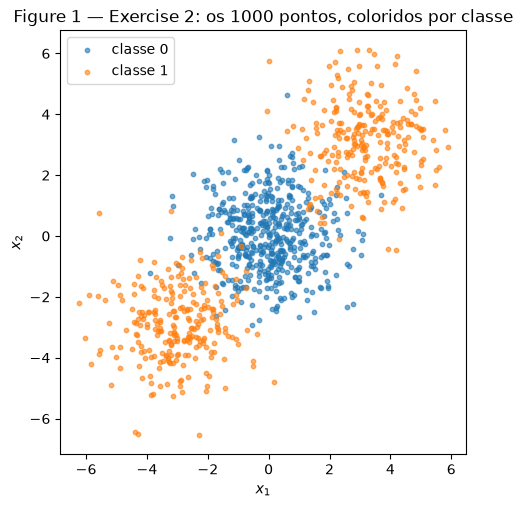

In [3]:
"""Exercise 2 — classificação binária que uma reta não resolve.

Gera figures/fig1.png, fig2.png, fig3.png e imprime os números do relatório.
Roda de qualquer diretório: python ex2_binary.py
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression


rng = np.random.default_rng(42)
COLORS = {0: "tab:blue", 1: "tab:orange"}

# ---------------------------------------------------------------- A — dados
# 500 pontos no centro (0, 0) e 250 em cada um dos centros (3, 3) e (-3, -3)
X, cluster = make_blobs(n_samples=[500, 250, 250], centers=[(0, 0), (3, 3), (-3, -3)],
                        cluster_std=1.2, random_state=42)
y = (cluster > 0).astype(int)                 # classe 1 = os dois clusters de fora
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"A) treino {X_train.shape}, teste {X_test.shape}, classe 1 no teste: {y_test.mean():.2f}")

fig, ax = plt.subplots(figsize=(6, 5.5))
for c in (0, 1):
    ax.scatter(*X[y == c].T, s=10, alpha=0.6, color=COLORS[c], label=f"classe {c}")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("Figure 1 — Exercise 2: os 1000 pontos, coloridos por classe")
ax.legend(); ax.set_aspect("equal")
plt.show()

### B — Establish the baseline

Treinei uma regressão logística no conjunto de treino. A acurácia no teste foi **47.50%**, abaixo dos 50% de
um chute. Os coeficientes saíram praticamente nulos: $\mathbf{w} = [0.0296,\ 0.0015]$ e intercepto $-0.0031$.
Com pesos tão pequenos a probabilidade prevista fica perto de 0.5 em todo o gráfico, e o modelo previu
classe 1 para 44.5% dos pontos de teste.

In [4]:
# ---------------------------------------------------------------- B — baseline linear
logreg = LogisticRegression().fit(X_train, y_train)
base_acc = logreg.score(X_test, y_test)
print(f"B) regressão logística: acurácia no teste = {base_acc:.4f}")
print(f"   coeficientes = {logreg.coef_[0].round(4)}, intercepto = {logreg.intercept_[0]:.4f}")
print(f"   fração do teste prevista como classe 1 = {logreg.predict(X_test).mean():.3f}")

B) regressão logística: acurácia no teste = 0.4750
   coeficientes = [0.0296 0.0015], intercepto = -0.0031
   fração do teste prevista como classe 1 = 0.445


### C — Implement the MLP

**Arquitetura e treino.** Rede `[2, 8, 1]`: 2 entradas, uma camada oculta com 8 neurônios tanh e 1 saída
sigmoide, com 33 parâmetros. Usei entropia cruzada binária como perda, taxa de aprendizado $\eta = 0.5$ e
**2000 épocas** em lote completo.

**Gradientes.** Com $\hat y = \sigma(u)$ e $L = -[y\log\hat y + (1-y)\log(1-\hat y)]$, a derivada da sigmoide
$\hat y(1 - \hat y)$ cancela com o denominador da perda e sobra $\partial L/\partial u = \hat y - y$. Na média
sobre $N$ amostras, o delta da saída é $\delta = (\hat{\mathbf{y}} - \mathbf{y})/N$. A partir dele, para cada
camada (da última para a primeira):

$$\frac{\partial L}{\partial W} = \delta^\top \mathbf{a}_{\text{anterior}}, \qquad
\frac{\partial L}{\partial \mathbf{b}} = \textstyle\sum \delta, \qquad
\delta_{\text{anterior}} = (\delta\, W) \odot (1 - \mathbf{a}_{\text{anterior}}^2)$$

e o update é $W \leftarrow W - \eta\,\partial L/\partial W$, $\mathbf{b} \leftarrow \mathbf{b} - \eta\,\partial L/\partial \mathbf{b}$.

**Resultado.** A perda de treino caiu de 0.7248 na primeira época para 0.1051 na última. A acurácia foi
96.75% no treino e **91.50% no teste**.

*(Figure 2: na saída da célula de código.)*

*(Figure 3: na saída da célula de código.)*

C) arquitetura [2, 8, 1] (tanh na oculta, sigmoide na saída), lr = 0.5, 2000 épocas, 33 parâmetros
   perda de treino: inicial 0.7248, final 0.1051
   acurácia: treino 0.9675, teste 0.9150


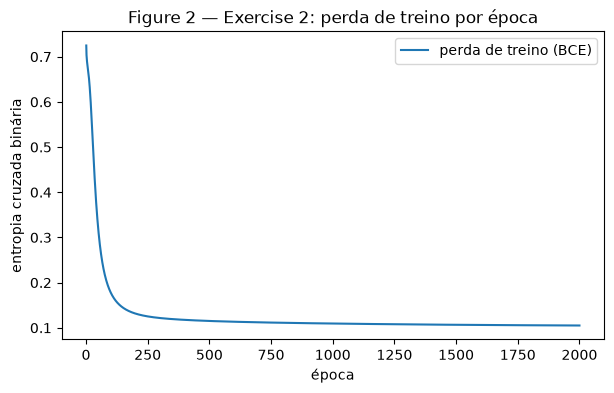

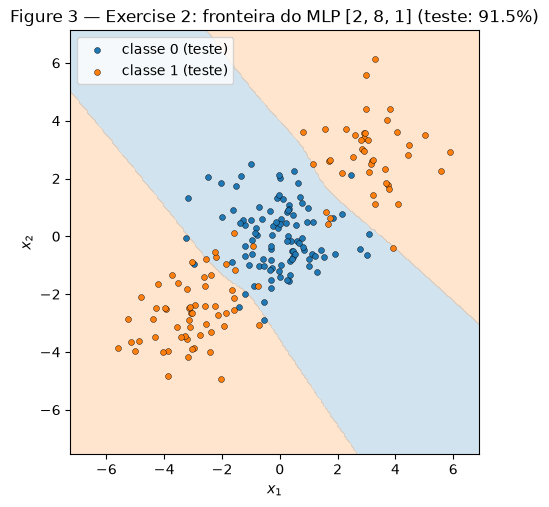

In [5]:
# ---------------------------------------------------------------- C — MLP
SIZES, LR, EPOCHS = [2, 8, 1], 0.5, 2000
model = MLP(SIZES, output="sigmoid", lr=LR, rng=rng)
history = model.fit(X_train, y_train[:, None], EPOCHS)
acc_train = (model.predict(X_train) == y_train).mean()
acc_test = (model.predict(X_test) == y_test).mean()
print(f"C) arquitetura {SIZES} (tanh na oculta, sigmoide na saída), lr = {LR}, {EPOCHS} épocas, "
      f"{model.n_params()} parâmetros")
print(f"   perda de treino: inicial {history[0]:.4f}, final {history[-1]:.4f}")
print(f"   acurácia: treino {acc_train:.4f}, teste {acc_test:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, EPOCHS + 1), history, label="perda de treino (BCE)")
ax.set_xlabel("época"); ax.set_ylabel("entropia cruzada binária")
ax.set_title("Figure 2 — Exercise 2: perda de treino por época")
ax.legend()
plt.show()

# Fronteira de decisão: avalia a rede numa grade e pinta as duas regiões
x1, x2 = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
                     np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))
grid_pred = model.predict(np.c_[x1.ravel(), x2.ravel()]).reshape(x1.shape)
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.contourf(x1, x2, grid_pred, levels=[-0.5, 0.5, 1.5], colors=[COLORS[0], COLORS[1]], alpha=0.2)
for c in (0, 1):
    ax.scatter(*X_test[y_test == c].T, s=18, color=COLORS[c], edgecolors="k", linewidths=0.3,
               label=f"classe {c} (teste)")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title(f"Figure 3 — Exercise 2: fronteira do MLP {SIZES} (teste: {acc_test:.1%})")
ax.legend(); ax.set_aspect("equal")
plt.show()

In [6]:
# ---------------------------------------------------------------- D — forma da região da classe 1
# Onde a região da classe 1 fica: proporção da grade em cada lado da diagonal x1 + x2 = 0
region1 = grid_pred == 1
s = x1 + x2
print(f"D) região da classe 1: {region1.mean():.1%} da grade; "
      f"acima de x1+x2=0: {region1[s > 0].mean():.1%}, abaixo: {region1[s < 0].mean():.1%}")

D) região da classe 1: 56.5% da grade; acima de x1+x2=0: 53.1%, abaixo: 59.6%


### D — Analysis

**Por que a reta fica abaixo de 50% e o MLP passa de 90%?** Pela Figure 1, a classe 1 está dos dois lados da
classe 0, ao longo da diagonal: um cluster em (3, 3) e outro em (−3, −3). Uma reta divide o plano em só dois
semiplanos, então ela consegue no máximo deixar a classe 0 junto com um dos clusters de fora. Além disso, os
dados são simétricos em relação à origem: trocar $\mathbf{x}$ por $-\mathbf{x}$ não muda as classes. Qualquer
inclinação que ajuda a acertar o cluster de (3, 3) atrapalha na mesma medida no de (−3, −3), e a perda da
regressão logística fica mínima com os pesos perto de zero. Foi o que aconteceu: $\mathbf{w} \approx [0.03,\ 0.00]$,
probabilidade perto de 0.5 em todo lugar e uma reta quase vertical passando pelo meio, que divide as duas
classes ao meio. Isso dá cerca de 50%, e os 47.50% são esse chute mais a variação de uma amostra de teste de
200 pontos.

**Forma da região da classe 1.** Na Figure 3, a rede classifica como classe 0 uma faixa na diagonal que vai do
canto de cima à esquerda até o canto de baixo à direita, passando pela origem, e como classe 1 as duas regiões
fora dessa faixa: uma acima e à direita e outra abaixo e à esquerda. A região da classe 1 tem 56.5% da grade e
fica dos dois lados da reta $x_1 + x_2 = 0$ (53.1% da grade acima dela e 59.6% abaixo). Ela é formada por duas
partes separadas. Uma única reta sempre produz um semiplano de cada lado, então não consegue gerar uma classe
que fica dos dois lados da outra. A camada oculta resolve isso porque cada neurônio tanh gera uma fronteira
reta, e a saída combina essas retas. Com duas retas paralelas já dá para formar a faixa da classe 0.

---
## Exercise 3

**Multi-Class, Same Network.**

### A — Generate the data

Usei `make_classification` com `n_samples=1500`, `n_features=4`, `n_informative=4`, `n_redundant=0`,
`n_repeated=0`, `n_classes=3`, `n_clusters_per_class=2`, `class_sep=1.0` e `random_state=42`. Dividi em 80%
treino (1200 amostras) e 20% teste (300 amostras), com `stratify=y` e seed 42. O teste ficou com 100 amostras de
cada classe.

In [7]:
"""Exercise 3 — multiclasse com a mesma rede do Exercise 2.

Gera figures/fig4.png e fig5.png e imprime os números do relatório.
Roda de qualquer diretório: python ex3_multiclass.py
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix


rng = np.random.default_rng(42)

# ---------------------------------------------------------------- A — dados
X_train, X_test, y_train, y_test = load_multiclass()
print(f"A) treino {X_train.shape}, teste {X_test.shape}, amostras por classe no teste: {np.bincount(y_test)}")

A) treino (1200, 4), teste (300, 4), amostras por classe no teste: [100 100 100]


### B — Adapt the network

Para três classes, a saída passou a ter 3 neurônios com softmax, e a perda passou a ser a entropia cruzada
categórica:

$$\hat y_k = \frac{e^{u_k}}{\sum_j e^{u_j}}, \qquad L = -\sum_k y_k \log \hat y_k$$

com $\mathbf{y}$ em one-hot. **Derivada de $L$ em relação a $\mathbf{u}$.** Primeiro a derivada da softmax:

$$\frac{\partial \hat y_k}{\partial u_j} =
\begin{cases} \hat y_k(1 - \hat y_k) & k = j \\ -\hat y_k\,\hat y_j & k \ne j \end{cases}
\;=\; \hat y_k(\delta_{kj} - \hat y_j)$$

Pela regra da cadeia:

$$\frac{\partial L}{\partial u_j} = \sum_k \frac{\partial L}{\partial \hat y_k}\frac{\partial \hat y_k}{\partial u_j}
= \sum_k \left(-\frac{y_k}{\hat y_k}\right)\hat y_k(\delta_{kj} - \hat y_j)
= -y_j + \hat y_j \sum_k y_k = \hat y_j - y_j$$

porque $\sum_k y_k = 1$ no one-hot. Então $\partial L/\partial \mathbf{u} = \hat{\mathbf{y}} - \mathbf{y}$, a mesma
forma do caso sigmoide + entropia cruzada binária. Por isso o backward do Exercise 2 serve aqui sem mudança: a
classe `MLP` só recebe `output="softmax"` e os tamanhos `[4, 16, 3]` como argumentos. O forward, o backward e
o update são exatamente os mesmos.

### C — Train and evaluate

**Arquitetura e hiperparâmetros.** Rede `[4, 16, 3]`: 4 entradas, uma camada oculta com 16 neurônios tanh e
3 saídas softmax, com 131 parâmetros. Usei $\eta = 0.5$ e **2000 épocas** em lote completo.

**Resultado.** A perda de treino caiu de 1.1963 para 0.2504. A acurácia foi 91.50% no treino e
**84.67% no teste**.

*(Figure 4: na saída da célula de código.)*

*(Figure 5: na saída da célula de código.)*

Matriz de confusão (linha = classe real, coluna = classe prevista):

| real \ prevista | classe 0 | classe 1 | classe 2 |
|---|---|---|---|
| classe 0 | 88 | 9 | 3 |
| classe 1 | 12 | 77 | 11 |
| classe 2 | 6 | 5 | 89 |

C) arquitetura [4, 16, 3] (tanh na oculta, softmax na saída), lr = 0.5, 2000 épocas, 131 parâmetros
   perda de treino: inicial 1.1963, final 0.2504
   acurácia: treino 0.9150, teste 0.8467


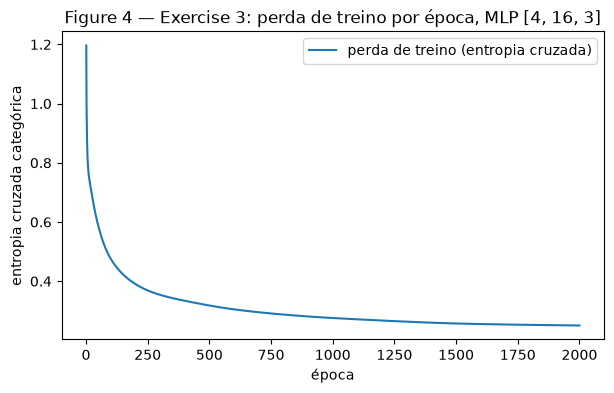

   matriz de confusão (linha = real, coluna = prevista):
[[88  9  3]
 [12 77 11]
 [ 6  5 89]]


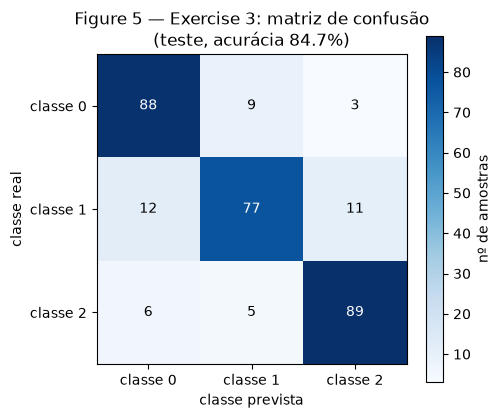

In [8]:
# ---------------------------------------------------------------- C — treino (a rede é a do Exercise 2)
SIZES, LR, EPOCHS = [4, 16, 3], 0.5, 2000
model = MLP(SIZES, output="softmax", lr=LR, rng=rng)
history = model.fit(X_train, one_hot(y_train), EPOCHS)
pred = model.predict(X_test)
acc_train = (model.predict(X_train) == y_train).mean()
acc_test = (pred == y_test).mean()
print(f"C) arquitetura {SIZES} (tanh na oculta, softmax na saída), lr = {LR}, {EPOCHS} épocas, "
      f"{model.n_params()} parâmetros")
print(f"   perda de treino: inicial {history[0]:.4f}, final {history[-1]:.4f}")
print(f"   acurácia: treino {acc_train:.4f}, teste {acc_test:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, EPOCHS + 1), history, label="perda de treino (entropia cruzada)")
ax.set_xlabel("época"); ax.set_ylabel("entropia cruzada categórica")
ax.set_title(f"Figure 4 — Exercise 3: perda de treino por época, MLP {SIZES}")
ax.legend()
plt.show()

cm = confusion_matrix(y_test, pred)
print("   matriz de confusão (linha = real, coluna = prevista):")
print(cm)
fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(3)); ax.set_yticks(range(3))
ax.set_xticklabels([f"classe {k}" for k in range(3)])
ax.set_yticklabels([f"classe {k}" for k in range(3)])
ax.set_xlabel("classe prevista"); ax.set_ylabel("classe real")
ax.set_title(f"Figure 5 — Exercise 3: matriz de confusão\n(teste, acurácia {acc_test:.1%})")
fig.colorbar(im, ax=ax, label="nº de amostras")
plt.show()

In [9]:
# ---------------------------------------------------------------- D — par mais confundido
pairs = {(i, j): cm[i, j] + cm[j, i] for i in range(3) for j in range(i + 1, 3)}
worst = max(pairs, key=pairs.get)
print(f"D) erros por par de classes (nos dois sentidos): {pairs}; mais confundido: {worst}")


# Estrutura dos clusters: com shuffle=False o make_classification devolve os mesmos pontos e rótulos
# (só a ordem das linhas e das colunas muda, o que não altera distâncias), agrupados em blocos de 250
# por cluster (6 clusters = 2 por classe). Isso permite medir onde cada cluster está.
from sklearn.datasets import make_classification
X_all, y_all = make_classification(n_samples=1500, n_features=4, n_informative=4, n_redundant=0,
                                   n_repeated=0, n_classes=3, n_clusters_per_class=2,
                                   class_sep=1.0, random_state=42, shuffle=False)
cluster_id = np.repeat(np.arange(6), 250)
centers = np.vstack([X_all[cluster_id == k].mean(0) for k in range(6)])
cluster_class = [int(np.bincount(y_all[cluster_id == k]).argmax()) for k in range(6)]
print("   centros dos 6 clusters (classe: centro):")
for k in range(6):
    print(f"   cluster {k} (classe {cluster_class[k]}): {centers[k].round(2)}")
print("   pares de clusters de classes diferentes a menos de 2.5 de distância (vizinhos no hipercubo):")
for i in range(6):
    for j in range(i + 1, 6):
        d = np.linalg.norm(centers[i] - centers[j])
        if cluster_class[i] != cluster_class[j] and d < 2.5:
            print(f"   cluster {i} (classe {cluster_class[i]}) - cluster {j} (classe {cluster_class[j]}): {d:.2f}")
for (i, j) in pairs:
    d = min(np.linalg.norm(centers[a] - centers[b]) for a in range(6) for b in range(6)
            if {cluster_class[a], cluster_class[b]} == {i, j})
    print(f"   classes {i} e {j}: clusters mais próximos a {d:.2f}")
print(f"   rótulos trocados pelo flip_y padrão (1%): {(y_all != np.array(cluster_class)[cluster_id]).sum()} de 1500")
spread = [np.linalg.norm(X_all[cluster_id == k] - centers[k], axis=1).mean() for k in range(6)]
print(f"   distância média de um ponto ao centro do próprio cluster: {np.round(spread, 2).tolist()}")
mid_14 = (centers[1] + centers[4]) / 2
print(f"   cluster 2 (classe 2) até o ponto médio dos clusters 1 e 4 (classe 1): {np.linalg.norm(centers[2] - mid_14):.2f}; "
      f"metade da distância entre 1 e 4: {np.linalg.norm(centers[1] - centers[4]) / 2:.2f}")

logreg = LogisticRegression(max_iter=1000).fit(X_train, y_train)
print(f"D) regressão logística (baseline linear): acurácia no teste = {logreg.score(X_test, y_test):.4f}")

D) erros por par de classes (nos dois sentidos): {(0, 1): np.int64(21), (0, 2): np.int64(9), (1, 2): np.int64(16)}; mais confundido: (0, 1)
   centros dos 6 clusters (classe: centro):
   cluster 0 (classe 0): [-1.12 -0.98 -0.88 -1.06]
   cluster 1 (classe 1): [-0.83 -0.92 -1.09  0.94]
   cluster 2 (classe 2): [-0.94  1.16 -1.02  0.97]
   cluster 3 (classe 0): [ 0.94  0.96  1.05 -1.14]
   cluster 4 (classe 1): [ 0.97  1.03 -1.02  1.06]
   cluster 5 (classe 2): [ 0.89 -1.17  0.93  1.01]
   pares de clusters de classes diferentes a menos de 2.5 de distância (vizinhos no hipercubo):
   cluster 0 (classe 0) - cluster 1 (classe 1): 2.03
   cluster 1 (classe 1) - cluster 2 (classe 2): 2.08
   cluster 2 (classe 2) - cluster 4 (classe 1): 1.92
   classes 0 e 1: clusters mais próximos a 2.03
   classes 0 e 2: clusters mais próximos a 2.96
   classes 1 e 2: clusters mais próximos a 1.92
   rótulos trocados pelo flip_y padrão (1%): 11 de 1500
   distância média de um ponto ao centro do próprio clu

### D — Analysis

**Par mais confundido.** Somando os erros nos dois sentidos, o par mais confundido é **classe 0 e classe 1**,
com 21 erros (9 + 12). Depois vêm classe 1 e classe 2 com 16 erros (11 + 5) e classe 0 e classe 2 com 9
erros (3 + 6). A classe 1 é a que a rede mais erra: 77 acertos em 100.

Para explicar isso pela estrutura dos clusters, gerei os mesmos dados com `shuffle=False`, que devolve os
mesmos pontos agrupados por cluster, e calculei o centro de cada um dos 6 clusters. O `make_classification`
coloca os clusters em vértices de um hipercubo em 4 dimensões, com coordenadas perto de ±1. Dois vértices
vizinhos (que diferem em uma coordenada só) ficam a uma distância de cerca de 2, e os outros a 2.6 ou mais.
Os pares de clusters de classes diferentes que são vizinhos são:

| clusters vizinhos | classes | distância entre os centros |
|---|---|---|
| cluster 0 e cluster 1 | 0 e 1 | 2.03 |
| cluster 1 e cluster 2 | 1 e 2 | 2.08 |
| cluster 2 e cluster 4 | 2 e 1 | 1.92 |

A classe 1 é a única que tem cluster vizinho das duas outras classes, e por isso é a mais difícil. As classes
0 e 1 têm um par de clusters vizinhos com centros a 2.03 de distância. Só que cada cluster é bem espalhado: a
distância média de um ponto até o centro do próprio cluster é 2.31 no cluster 0 e 2.50 no cluster 1, maior que
a distância entre os dois centros. Então essas duas nuvens se misturam bastante, e a rede confunde as duas. Já as classes 0 e 2 não têm nenhum par
vizinho (os clusters mais próximos estão a 2.96), e são as menos confundidas, com 9 erros. Uma ressalva: pela
geometria, as classes 1 e 2 têm dois pares vizinhos, e mesmo assim ficaram em segundo lugar (16 erros contra
21). Com 100 amostras por classe no teste, uma diferença de 5 erros está dentro da variação esperada, então eu
não daria muito peso à ordem entre esses dois pares. A conclusão mais sólida é que os erros acontecem entre
classes com clusters vizinhos no hipercubo e que a classe 1, que encosta nas outras duas, é a mais afetada.
Também existe um pouco de ruído nos rótulos: o `make_classification` troca 1% dos rótulos por padrão
(`flip_y=0.01`), o que deu 11 das 1500 amostras com rótulo trocado.

**Comparação com a baseline.** A regressão logística acertou **66.33%** no teste, contra 84.67% do MLP, uma
diferença de 18.3 p.p. Cada classe é formada por dois clusters em vértices diferentes do hipercubo. A
regressão logística só consegue dar a cada classe uma região convexa (em um pedaço só e sem buracos), então a
região de uma classe precisa conter o caminho entre os seus dois clusters. Aqui isso atrapalha. Por exemplo, o
cluster 2 (classe 2) fica no meio do caminho entre os dois clusters da classe 1 (clusters 1 e 4): ele está a
1.50 do ponto médio entre eles, e a metade da distância entre eles é 1.33. Uma região convexa que pegue os dois
clusters da classe 1 acaba pegando boa parte do cluster 2 junto. A camada oculta resolve isso porque deixa a
rede montar, para cada classe, uma região formada por partes separadas, como no Exercise 2.

---
## Exercise 4

**Does a Second Hidden Layer Help?**

### A — Train the deeper network

Mantive os mesmos dados, a mesma divisão, $\eta = 0.5$, 2000 épocas e a mesma seed do Exercise 3. A única
mudança foi a profundidade: a rede `[4, 16, 16, 3]` tem **duas camadas ocultas** com 16 neurônios tanh cada e
403 parâmetros. Com seed 42 ela chegou a perda de treino 0.1691 e **83.67% de acurácia no teste**.

A) Exercise 3 (1 camada oculta): [4, 16, 3], seed 42 -> perda final 0.2504, acurácia no teste 0.8467


   Exercise 3 (1 camada oculta): acurácias por seed [0.8467, 0.83, 0.8667], perdas finais [0.2504, 0.2542, 0.273]


A) Exercise 4 (2 camadas ocultas): [4, 16, 16, 3], seed 42 -> perda final 0.1691, acurácia no teste 0.8367


   Exercise 4 (2 camadas ocultas): acurácias por seed [0.8367, 0.8567, 0.8333], perdas finais [0.1691, 0.1624, 0.1589]
B) tabela de comparação:
                                camadas ocultas  parâmetros  perda final de treino (seed 42)  acurácia no teste (seed 42)  perda final de treino (média 3 seeds)  acurácia no treino (média 3 seeds)  acurácia no teste (média 3 seeds)  acurácia no teste (desvio 3 seeds)
modelo                                                                                                                                                                                                                                                                     
Exercise 3 (1 camada oculta)                  1         131                           0.2504                       0.8467                                 0.2592                              0.9056                             0.8478                              0.0150
Exercise 4 (2 camadas ocultas)                2     

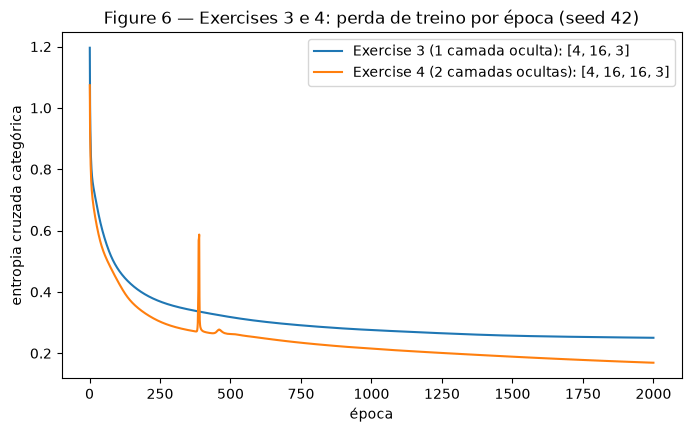

In [10]:
"""Exercise 4 — uma segunda camada oculta ajuda?

Mesmos dados, mesma divisão, mesma taxa de aprendizado e mesmo número de épocas do
Exercise 3. A única mudança é a profundidade. Gera figures/fig6.png e imprime a tabela.
Roda de qualquer diretório: python ex4_depth.py
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



X_train, X_test, y_train, y_test = load_multiclass()
Y_train = one_hot(y_train)

LR, EPOCHS = 0.5, 2000                       # mesmo orçamento do Exercise 3
ARCHS = {"Exercise 3 (1 camada oculta)": [4, 16, 3],
         "Exercise 4 (2 camadas ocultas)": [4, 16, 16, 3]}
SEEDS = [42, 43, 44]                         # seed 42 é a execução principal; 43 e 44 entram na média


def run(sizes, seed):
    """Treina uma rede com pesos iniciais vindos de default_rng(seed)."""
    rng = np.random.default_rng(seed)
    model = MLP(sizes, output="softmax", lr=LR, rng=rng)
    history = model.fit(X_train, Y_train, EPOCHS)
    return model, history, (model.predict(X_test) == y_test).mean(), (model.predict(X_train) == y_train).mean()


rows, curves = [], {}
for name, sizes in ARCHS.items():
    accs, losses, accs_train = [], [], []
    for seed in SEEDS:
        model, history, acc, acc_train = run(sizes, seed)
        accs.append(acc); losses.append(history[-1]); accs_train.append(acc_train)
        if seed == 42:
            curves[name] = history
            print(f"A) {name}: {sizes}, seed 42 -> perda final {history[-1]:.4f}, acurácia no teste {acc:.4f}")
    print(f"   {name}: acurácias por seed {np.round(accs, 4).tolist()}, perdas finais {np.round(losses, 4).tolist()}")
    rows.append({"modelo": name, "camadas ocultas": len(sizes) - 2, "parâmetros": model.n_params(),
                 "perda final de treino (seed 42)": losses[0], "acurácia no teste (seed 42)": accs[0],
                 "perda final de treino (média 3 seeds)": np.mean(losses),
                 "acurácia no treino (média 3 seeds)": np.mean(accs_train),
                 "acurácia no teste (média 3 seeds)": np.mean(accs),
                 "acurácia no teste (desvio 3 seeds)": np.std(accs)})

table = pd.DataFrame(rows).set_index("modelo")
print("B) tabela de comparação:")
print(table.round(4).to_string())
diff = rows[1]["acurácia no teste (média 3 seeds)"] - rows[0]["acurácia no teste (média 3 seeds)"]
print(f"B) diferença de acurácia (Ex. 4 - Ex. 3), média de 3 seeds: {diff * 100:+.2f} p.p.")

# Estabilidade do treino (seed 42): em quantas épocas a perda subiu em vez de cair
for name, history in curves.items():
    rises = np.diff(history)
    msg = f"C) {name}: a perda subiu em {(rises > 0).sum()} de {EPOCHS} épocas"
    if (rises > 0).any():
        k = rises.argmax()                      # maior subida: da época k+1 para a época k+2
        msg += f"; maior subida na época {k + 2}: {history[k]:.3f} -> pico {history[k:k + 5].max():.3f}"
    print(msg)

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, history in curves.items():
    ax.plot(np.arange(1, EPOCHS + 1), history, label=f"{name}: {ARCHS[name]}")
ax.set_xlabel("época"); ax.set_ylabel("entropia cruzada categórica")
ax.set_title("Figure 6 — Exercises 3 e 4: perda de treino por época (seed 42)")
ax.legend()
plt.show()

### B — Compare

*(Figure 6: na saída da célula de código.)*

Rodei os dois modelos com as seeds 42, 43 e 44 (a seed muda só a inicialização dos pesos; os dados e a divisão
são sempre os mesmos).

| modelo | camadas ocultas | parâmetros | perda final de treino (seed 42) | acurácia no teste (seed 42) | perda final de treino (média de 3 seeds) | acurácia no treino (média de 3 seeds) | acurácia no teste (média de 3 seeds) |
|---|---|---|---|---|---|---|---|
| Exercise 3 `[4, 16, 3]` | 1 | 131 | 0.2504 | 84.67% | 0.2592 | 90.56% | **84.78%** |
| Exercise 4 `[4, 16, 16, 3]` | 2 | 403 | 0.1691 | 83.67% | 0.1635 | 94.28% | **84.22%** |

Acurácias no teste por seed (42, 43, 44): Exercise 3 com 84.67%, 83.00% e 86.67%; Exercise 4 com 83.67%,
85.67% e 83.33%. Na média, a rede mais funda ficou **0.56 p.p. abaixo** da rede do Exercise 3.

### C — Analysis

A segunda camada não ajudou. Na média de 3 seeds a rede mais funda ficou 0.56 p.p. abaixo. Essa diferença é
menor que a variação entre seeds (de 83.00% a 86.67% só no Exercise 3), então o mais honesto é dizer que as duas
redes empatam no teste e que a mais funda não trouxe ganho.

**Quantos clusters e que fronteira eles pedem.** Os dados têm 6 clusters gaussianos, 2 por classe, nos vértices
de um hipercubo em 4 dimensões. Para separar isso basta isolar cada cluster com alguns hiperplanos e juntar os
dois clusters de cada classe. Uma camada oculta com 16 neurônios tanh já gera 16 hiperplanos e consegue fazer
essa combinação na saída. O erro que sobra vem da sobreposição dos clusters vizinhos (o caso das classes 0 e 1
no Exercise 3) e dos rótulos trocados, e nenhuma arquitetura resolve isso.

**O que a segunda camada acrescenta e o que custa.** Na representação, a segunda camada combina as fronteiras
da primeira em regiões mais complexas, mas este problema não precisa disso. Na otimização, ela custa mais
parâmetros (403 contra 131) e um caminho mais longo para o gradiente, que passa por duas derivadas de tanh.
Na Figure 6 aparece um pico na perda da rede mais funda na época 387: com $\eta = 0.5$ um passo foi grande
demais, e a perda subiu de 0.405 para 0.587 antes de voltar a cair. No total, a perda da rede mais funda subiu
de uma época para a outra em 423 das 2000 épocas, enquanto a da rede de uma camada nunca subiu. Ou seja, com a
mesma taxa de aprendizado, a rede mais funda foi mais difícil de treinar.

**Perda de treino e acurácia no teste contam a mesma história?** Não. A rede mais funda chegou a uma perda de
treino bem menor (0.1635 contra 0.2592 na média) e acertou mais no treino (94.28% contra 90.56%), mas não
acertou mais no teste. A diferença entre treino e teste subiu de 5.8 p.p. para 10.1 p.p. Ou seja, a capacidade
extra foi usada para ajustar detalhes do conjunto de treino (incluindo a região de sobreposição e os rótulos
trocados) e não para aprender algo que generaliza.

**Que tipo de dado faria a profundidade valer a pena.** Dados com estrutura hierárquica ou composta, em que a
fronteira é feita de muitas partes que se repetem. Exemplos: uma paridade (XOR) em muitas dimensões, um
padrão de tabuleiro de xadrez com muitas casas, espirais entrelaçadas, ou imagens, em que as primeiras camadas
detectam bordas e as seguintes juntam bordas em formas. Nesses casos uma rede funda representa a fronteira com
bem menos neurônios do que uma rede rasa precisaria.

---
## Results summary

| # | Quantity | Value |
| --- | --- | --- |
| 1 | Ex. 1: $\mathbf{z}^{(1)}$ and $\mathbf{h}^{(1)}$ | $\mathbf{z}^{(1)}$ = [0.2700, −0.1800]; $\mathbf{h}^{(1)}$ = [0.2636, −0.1781] |
| 2 | Ex. 1: $u^{(2)}$, $\hat y$, and $L$ | $u^{(2)}$ = 0.3852; $\hat y$ = 0.3672; $L$ = 0.4004 |
| 3 | Ex. 1: the eight updated parameters | $W^{(2)}$ = [0.5866, −0.3585]; $b^{(2)}$ = 0.5284; $W^{(1)}$ = [[0.3764, −0.1306], [0.1523, 0.4191]]; $\mathbf{b}^{(1)}$ = [0.2528, −0.2954] |
| 4 | Ex. 2: linear baseline test accuracy | 47.50% (regressão logística) |
| 5 | Ex. 2: architecture and test accuracy | [2, 8, 1], tanh + sigmoide, η = 0.5, 2000 épocas: 91.50% |
| 6 | Ex. 3: architecture and test accuracy | [4, 16, 3], tanh + softmax, η = 0.5, 2000 épocas: 84.67% |
| 7 | Ex. 3: most-confused class pair | classes 0 e 1 (21 erros: 9 + 12) |
| 8 | Ex. 4: architecture and test accuracy | [4, 16, 16, 3], tanh + softmax, η = 0.5, 2000 épocas: 83.67% (seed 42); 84.22% na média de 3 seeds |
| 9 | Ex. 4: accuracy difference against Ex. 3 (mean over ≥3 seeds) | −0.56 p.p. (84.22% contra 84.78%, seeds 42, 43 e 44) |